In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_colwidth', None)

In [18]:
data1 = pd.read_csv('train.csv')
data2 = pd.read_csv('test.csv')

train_df = data1.copy()
test_df = data2.copy()

print("First 5 rows train data: \n", train_df.head())
print()
print("First 5 rows test data: \n", test_df.head())

First 5 rows train data: 
    id  Age  Flight Distance  Inflight wifi service  \
0   0   36              694                      4   
1   1   56              651                      5   
2   2   31             1371                      3   
3   3   10             1616                      3   
4   4   23              481                      3   

   Departure/Arrival time convenient  Ease of Online booking  Gate location  \
0                                  4                       4              3   
1                                  5                       5              5   
2                                  4                       2              5   
3                                  5                       3              3   
4                                  4                       3              4   

   Food and drink  Online boarding  Seat comfort  ...  Baggage handling  \
0               1                4             1  ...                 4   
1               5      

In [19]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11  On-board service                   699635 non-null

In [20]:
class_counts = train_df['satisfaction'].value_counts()
class_pct = train_df['satisfaction'].value_counts(normalize=True).mul(100).round(2)

print(class_counts)
print()
print(class_pct.rename("pct"))

satisfaction
False    389296
True     310339
Name: count, dtype: int64

satisfaction
False    55.64
True     44.36
Name: pct, dtype: float64


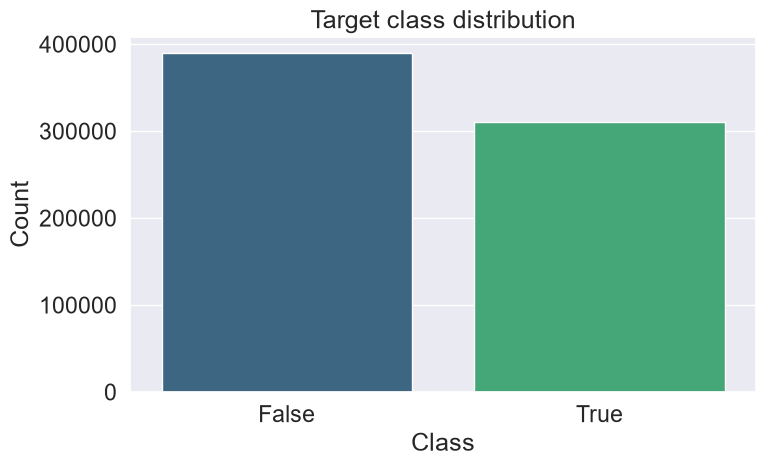

In [21]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=train_df, x=train_df['satisfaction'], order=class_counts.index, ax=ax, palette="viridis")
ax.set_title("Target class distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

In [22]:
train_df.shape, test_df.shape

((699635, 23), (299844, 22))

In [23]:
train_df.isna().sum()

id                                     0
Age                                    0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             292
Gender                                 0
Customer Type                          0
Type of Travel                         0
Class                                  0
satisfaction                           0
dtype: int64

In [24]:
map_enc_cols_train = [
    'satisfaction'
]

dummy_cols = [
    'Gender',
    'Customer Type',
    'Type of Travel',
    'Class'
]

for col in map_enc_cols_train:
    train_df[col] = train_df[col].astype(int)

for col in dummy_cols:
    dummies_train = pd.get_dummies(train_df[col], prefix=col, dtype=int)
    dummies_test = pd.get_dummies(test_df[col], prefix=col, dtype=int)

    dummies_test = dummies_test.reindex(columns=dummies_train.columns, fill_value=0)

    train_df = pd.concat([train_df, dummies_train], axis=1)
    test_df = pd.concat([test_df, dummies_test], axis=1)

In [25]:
num = train_df.select_dtypes(include='number')
cat = train_df.select_dtypes(exclude='number')

num = num.drop(columns='id')

In [26]:
num.describe()

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,satisfaction,Gender_Female,Gender_Male,Customer Type_Loyal Customer,Customer Type_disloyal Customer,Type of Travel_Business travel,Type of Travel_Personal Travel,Class_Business,Class_Eco,Class_Eco Plus
count,699635.000000,699635.000000,699635.000000,699635.00000,699635.00000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,...,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000
mean,39.001928,1353.778702,2.778722,3.15621,2.81324,3.013734,3.265644,3.364156,3.568950,3.453910,...,0.443573,0.497334,0.502666,0.824701,0.175299,0.711001,0.288999,0.489129,0.467964,0.042907
std,13.800943,954.422566,1.280419,1.47539,1.32955,1.254014,1.300202,1.288538,1.275333,1.308157,...,0.496806,0.499993,0.499993,0.380223,0.380223,0.453298,0.453298,0.499882,0.498973,0.202647
min,7.000000,67.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,27.000000,631.000000,2.000000,2.00000,2.00000,2.000000,2.000000,2.000000,3.000000,2.000000,...,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,40.000000,954.000000,3.000000,3.00000,3.00000,3.000000,3.000000,4.000000,4.000000,4.000000,...,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
75%,50.000000,1814.000000,4.000000,4.00000,4.00000,4.000000,4.000000,4.000000,5.000000,5.000000,...,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000
max,85.000000,4983.000000,5.000000,5.00000,5.00000,5.000000,5.000000,5.000000,5.000000,5.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


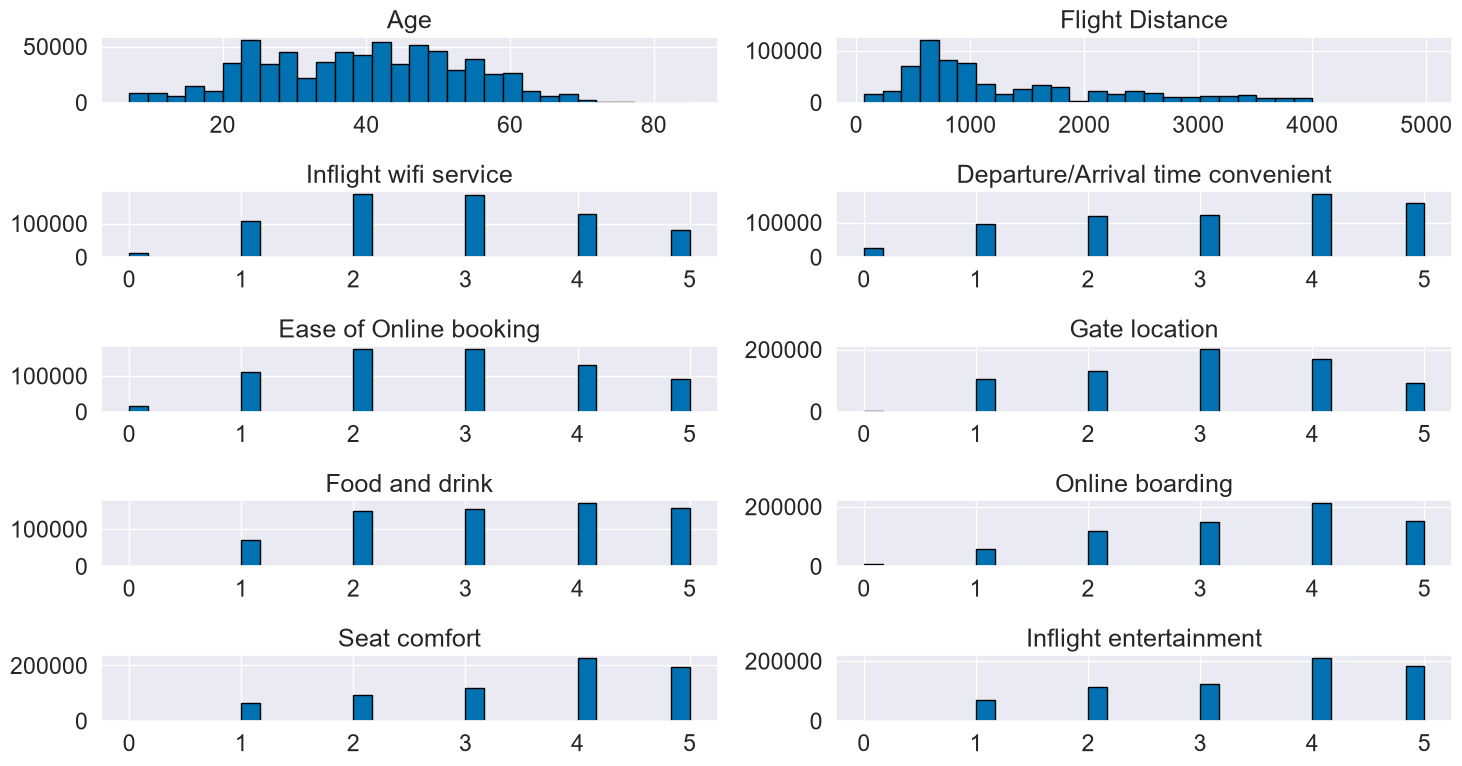

In [27]:
color = '#0072B2'

# grid size
nrows, ncols = 5, 2

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, 8))

axes = axes.flatten()

# Plot each numerical feature
for i, ax in enumerate(axes):
    if i >= len(num.columns):
        ax.set_visible(False)  # hide unesed plots
        continue
    ax.hist(num.iloc[:, i], bins=30, color=color, edgecolor='black')
    ax.set_title(num.columns[i])

plt.tight_layout()
plt.show()

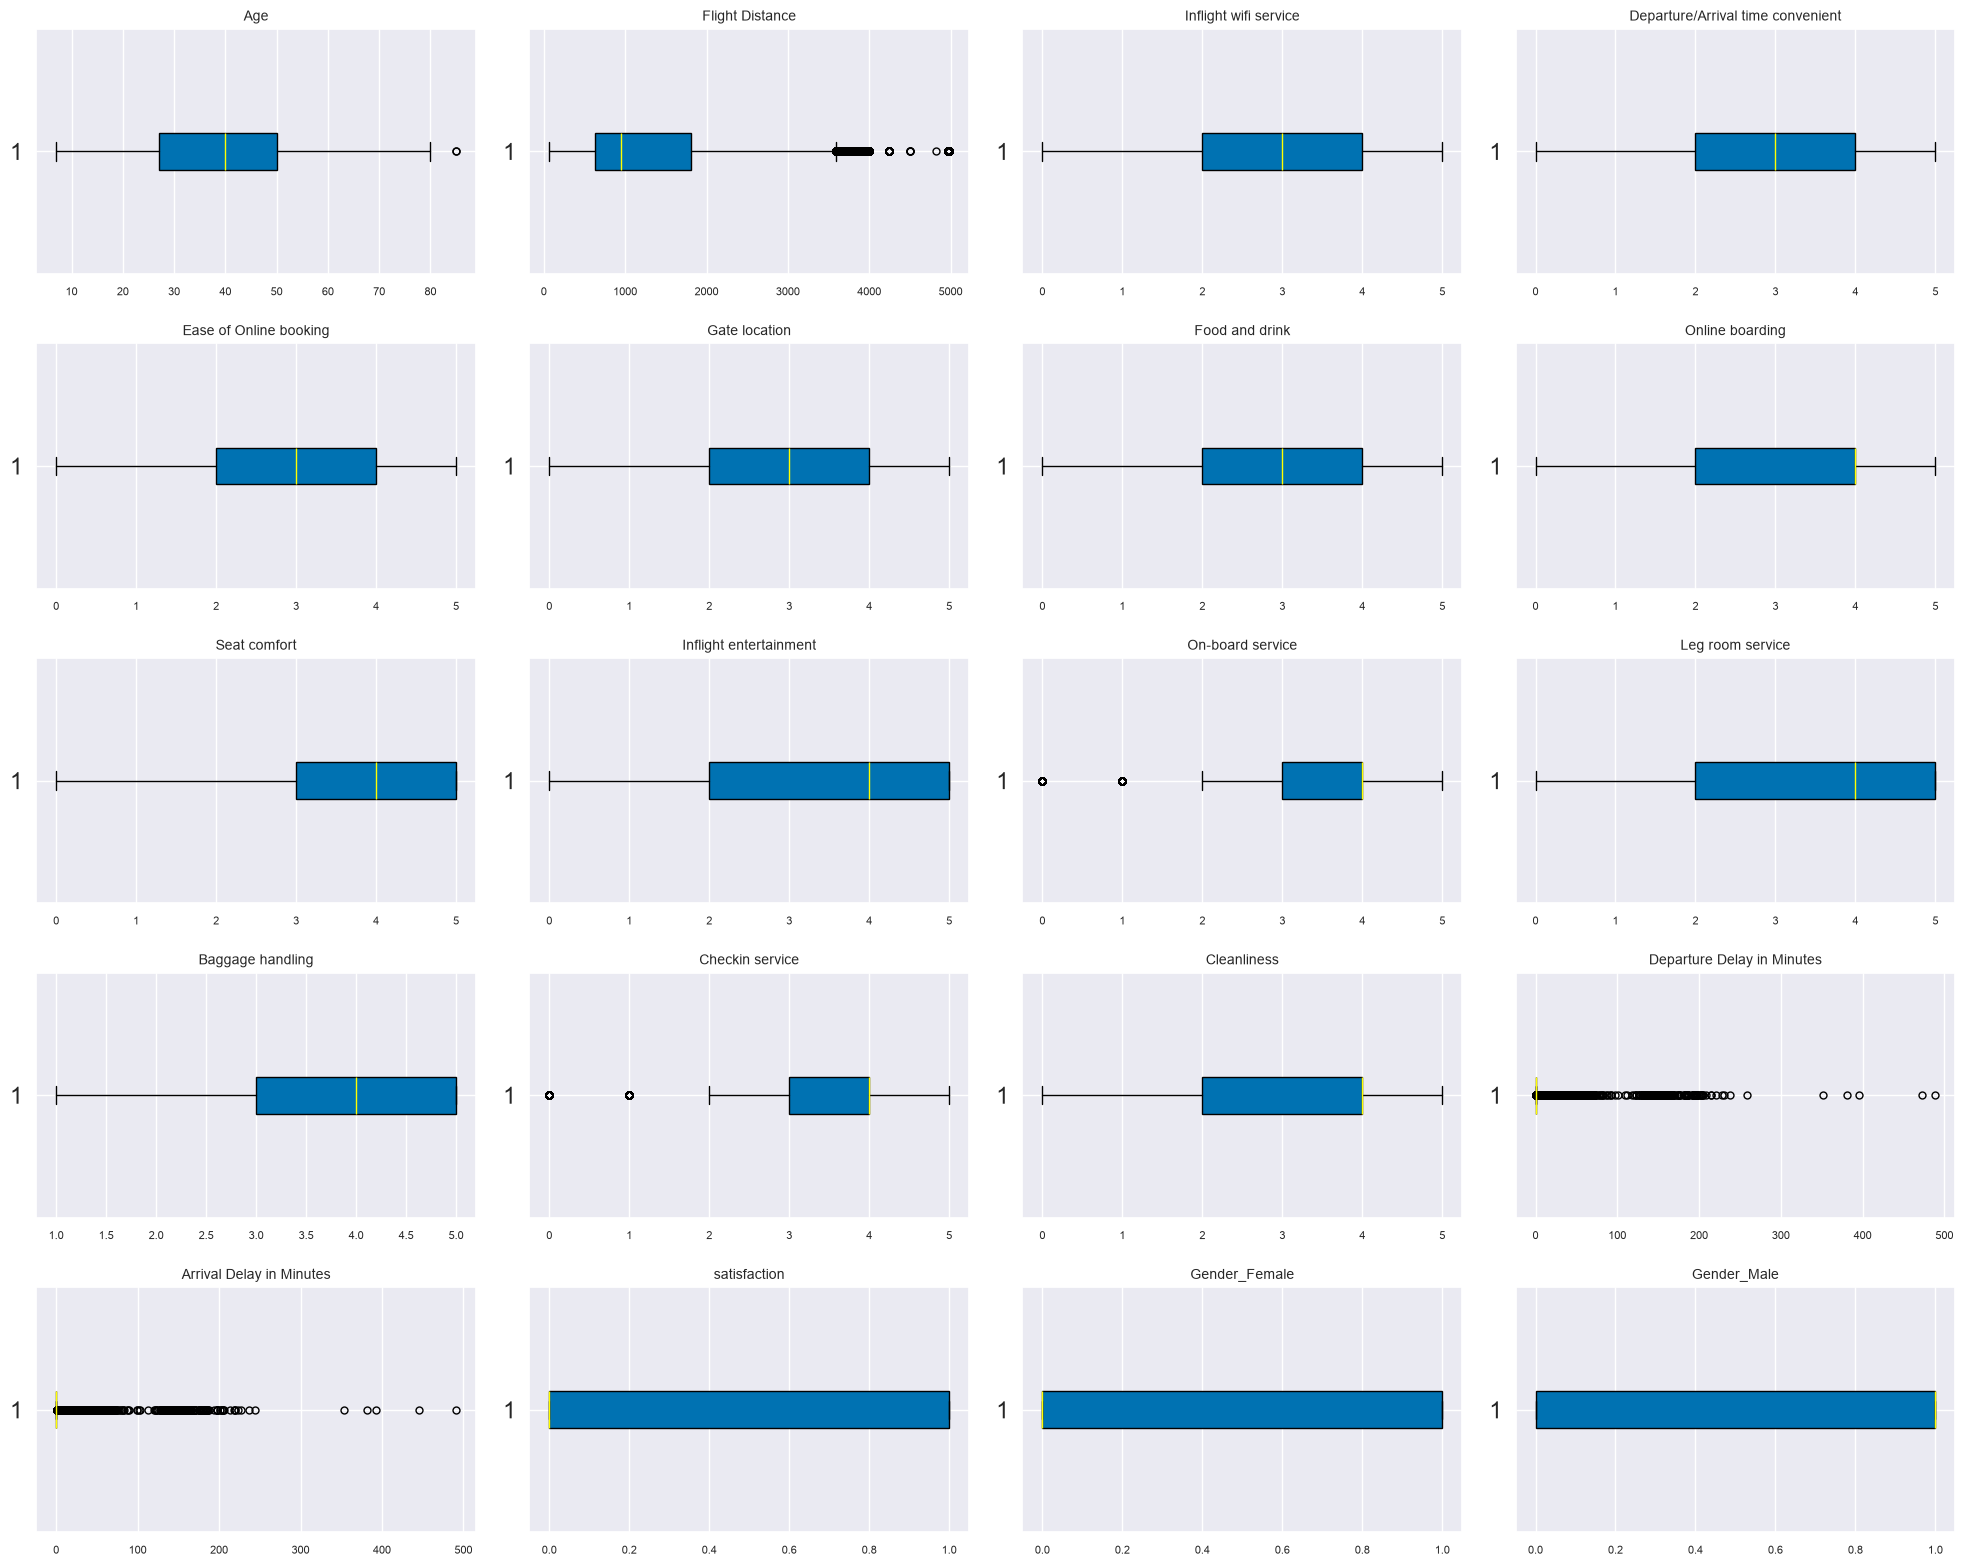

In [28]:
#boxplot numerical features

color = '#0072B2'

# grid size
nrows, ncols = 5, 4 

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(20, 16))

axes = axes.flatten()

for i, ax in enumerate(axes):
    if i >= len(num.columns):
        ax.set_visible(False)
        continue
    ax.boxplot(num.iloc[:, i].dropna(), vert=False, patch_artist=True, 
               boxprops=dict(facecolor=color, color='black'), 
               medianprops=dict(color='yellow'), whiskerprops=dict(color='black'), 
               capprops=dict(color='black'), flierprops=dict(marker='o', color='red', markersize=5))
    ax.set_title(num.columns[i], fontsize=10)
    ax.tick_params(axis='x', labelsize=8)

plt.tight_layout()
plt.show()

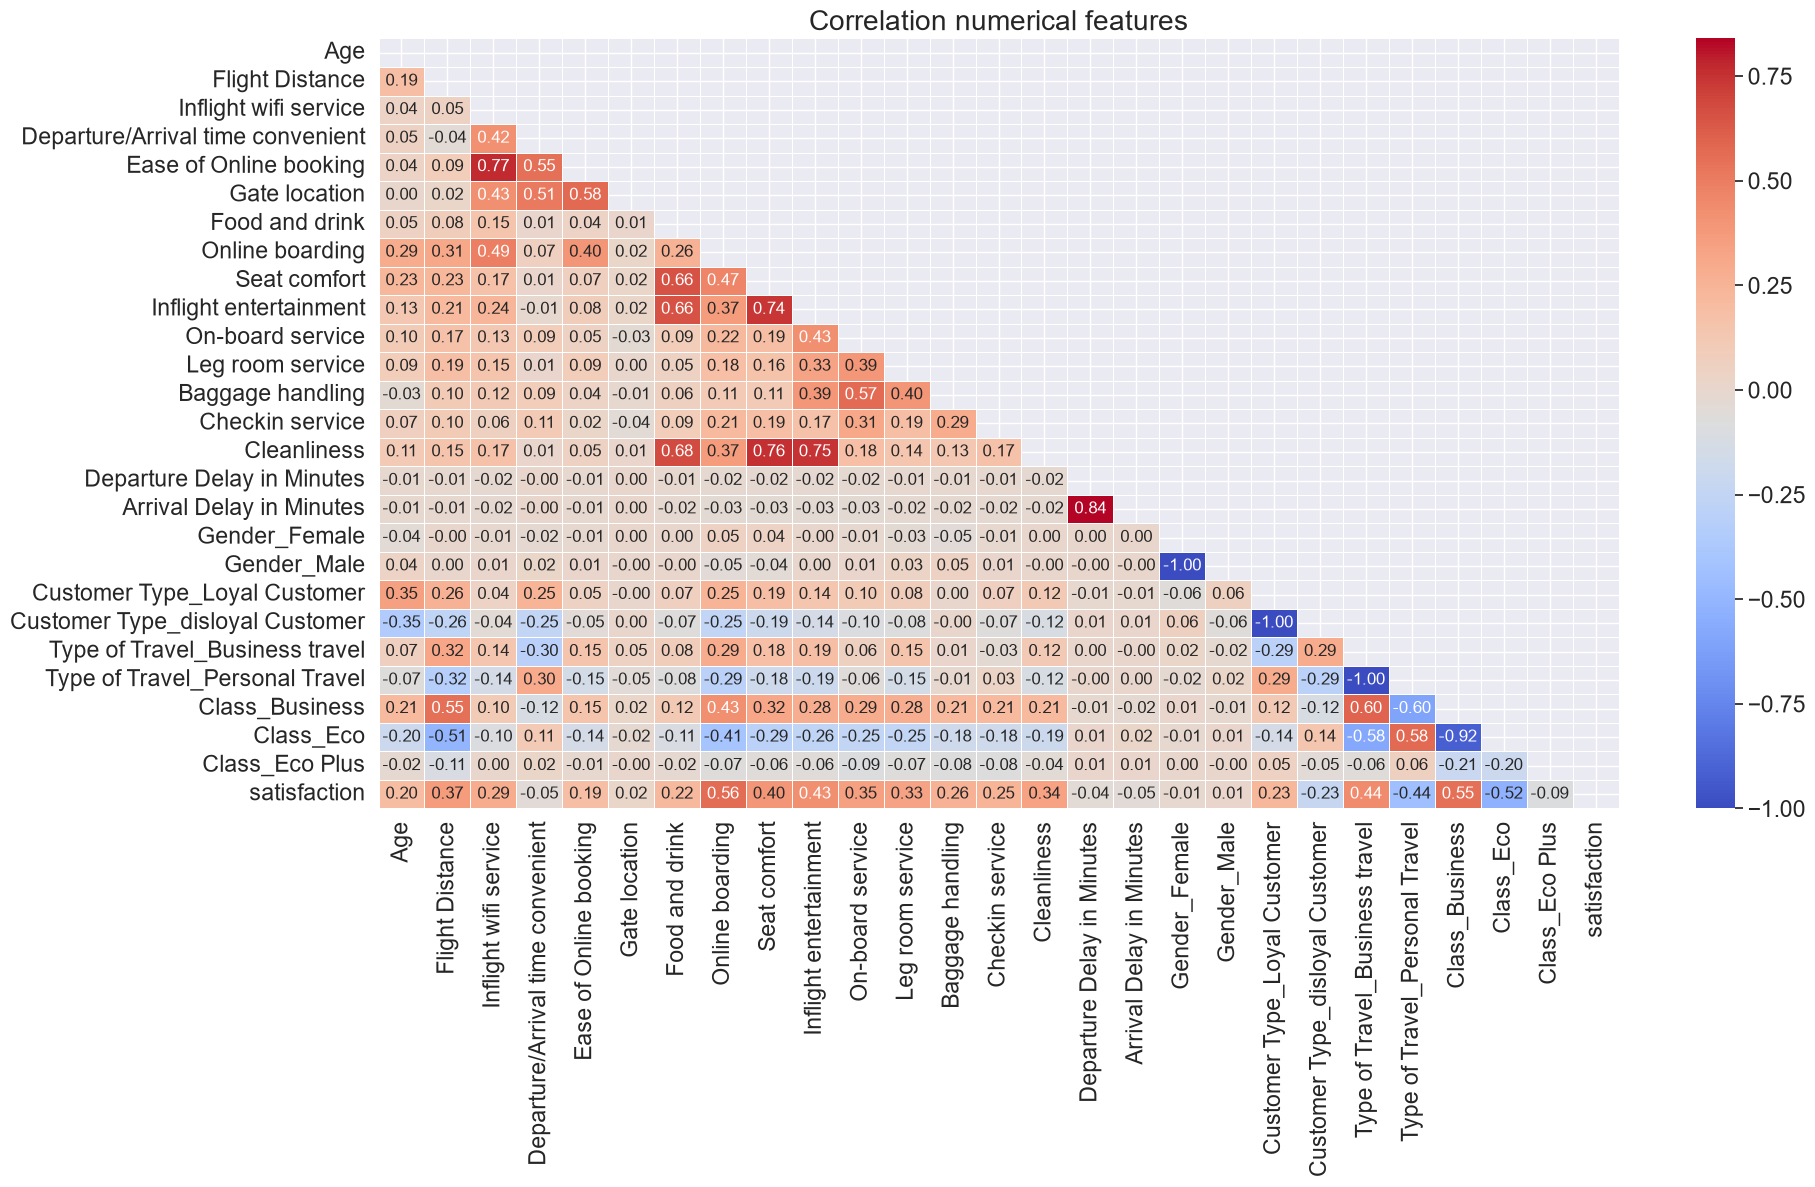

In [29]:
target_placeholder = num.pop('satisfaction')
num['satisfaction'] = target_placeholder

num_corr = round(num.corr(), 2)

# Correlation Matrix-Heatmap Plot
mask = np.zeros_like(num_corr)
mask[np.triu_indices_from(mask)] = True # optional, to hide repeat half of the matrix

f, ax = plt.subplots(figsize=(20, 10))
sns.set_theme(font_scale=1.5) # increase font size

ax = sns.heatmap(num_corr, mask=mask, annot=True, annot_kws={"size": 12}, linewidths=.5, cmap="coolwarm", fmt=".2f", ax=ax) # round to 2 decimal places
ax.set_title("Correlation numerical features", fontsize=20)
plt.show()

In [30]:
satisfied_df = train_df.loc[train_df['satisfaction'] == 1]

satisfied_df.describe()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,satisfaction,Gender_Female,Gender_Male,Customer Type_Loyal Customer,Customer Type_disloyal Customer,Type of Travel_Business travel,Type of Travel_Personal Travel,Class_Business,Class_Eco,Class_Eco Plus
count,310339.000000,310339.000000,310339.000000,310339.000000,310339.000000,310339.000000,310339.000000,310339.000000,310339.000000,310339.000000,...,310339.0,310339.000000,310339.000000,310339.000000,310339.000000,310339.000000,310339.000000,310339.000000,310339.000000,310339.000000
mean,349845.238301,42.135220,1749.335704,3.196434,3.074934,3.097477,3.045805,3.583188,4.171732,4.142428,...,1.0,0.491079,0.508921,0.920587,0.079413,0.936631,0.063369,0.799803,0.176771,0.023426
std,201778.462947,11.610186,1061.872046,1.494268,1.504689,1.488869,1.370170,1.195656,1.031118,1.003300,...,0.0,0.499921,0.499921,0.270383,0.270383,0.243627,0.243627,0.400148,0.381476,0.151252
min,1.000000,7.000000,67.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,175287.500000,34.000000,771.000000,2.000000,2.000000,2.000000,2.000000,3.000000,4.000000,4.000000,...,1.0,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000
50%,349779.000000,43.000000,1605.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,...,1.0,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000
75%,524261.500000,51.000000,2563.000000,4.000000,4.000000,4.000000,4.000000,5.000000,5.000000,5.000000,...,1.0,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000
max,699633.000000,85.000000,4983.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,...,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [31]:
dissatisfied_df = train_df.loc[train_df['satisfaction'] == 0]

dissatisfied_df.describe()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,satisfaction,Gender_Female,Gender_Male,Customer Type_Loyal Customer,Customer Type_disloyal Customer,Type of Travel_Business travel,Type of Travel_Personal Travel,Class_Business,Class_Eco,Class_Eco Plus
count,389296.000000,389296.000000,389296.000000,389296.00000,389296.000000,389296.000000,389296.000000,389296.000000,389296.000000,389296.000000,...,389296.0,389296.000000,389296.000000,389296.000000,389296.000000,389296.000000,389296.000000,389296.000000,389296.000000,389296.000000
mean,349794.488990,36.504131,1038.448556,2.44573,3.221002,2.586651,2.988168,3.012505,2.720372,3.111784,...,0.0,0.502320,0.497680,0.748264,0.251736,0.531133,0.468867,0.241467,0.700097,0.058436
std,202118.096564,14.858662,716.973683,0.95733,1.448348,1.137543,1.152429,1.324415,1.096353,1.284307,...,0.0,0.499995,0.499995,0.434011,0.434011,0.499030,0.499030,0.427973,0.458216,0.234567
min,0.000000,7.000000,67.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,174582.750000,25.000000,591.000000,2.00000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,...,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,349851.500000,35.000000,841.000000,2.00000,4.000000,3.000000,3.000000,3.000000,3.000000,3.000000,...,0.0,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,525083.250000,48.000000,1167.000000,3.00000,4.000000,3.000000,4.000000,4.000000,3.000000,4.000000,...,0.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000
max,699634.000000,85.000000,4983.000000,5.00000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,...,0.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


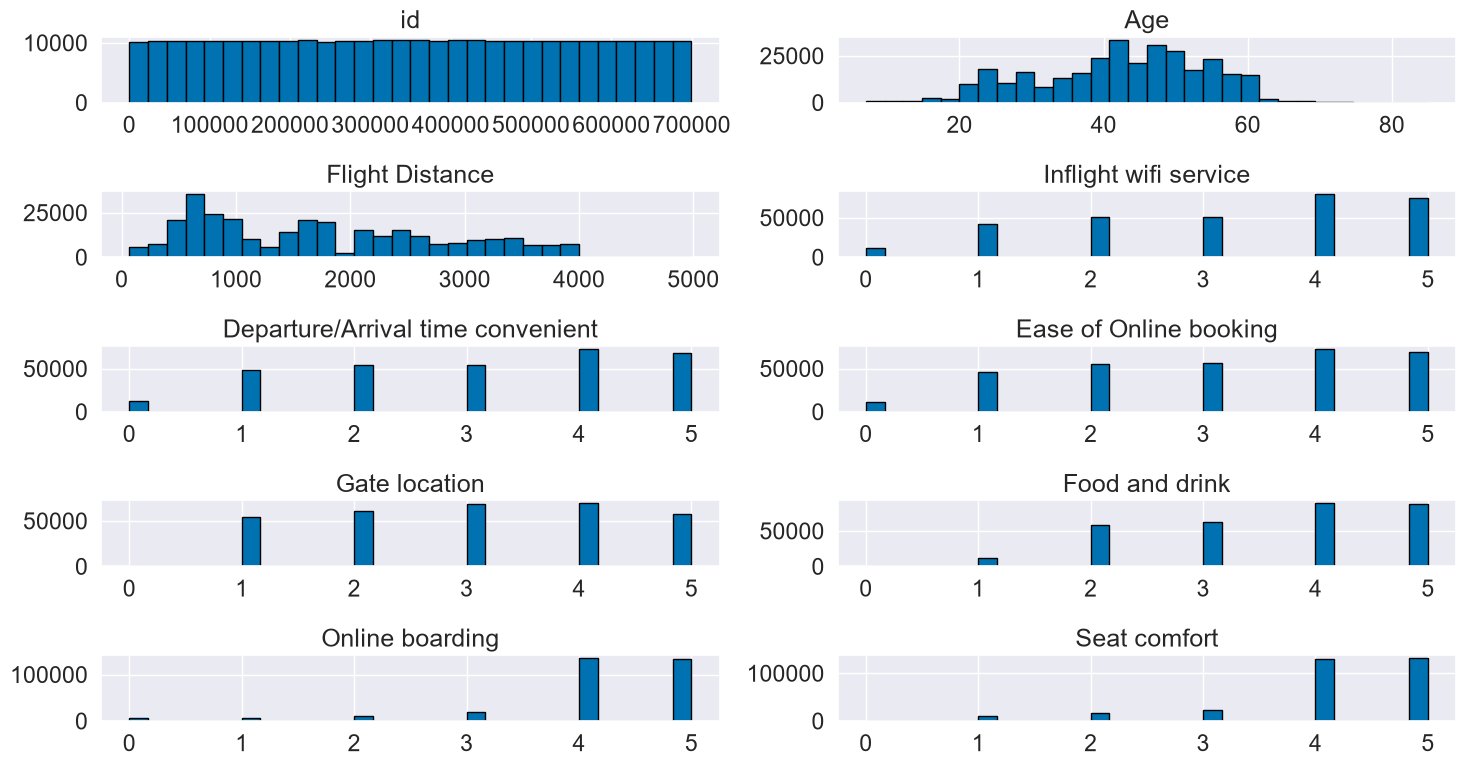

In [33]:
num_satisfied = satisfied_df.select_dtypes(include='number')

#plot numerical features

color = '#0072B2'

# grid size
nrows, ncols = 5, 2

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, 8))

axes = axes.flatten()

# Plot each numerical feature
for i, ax in enumerate(axes):
    if i >= len(num_satisfied.columns):
        ax.set_visible(False)  # hide unesed plots
        continue
    ax.hist(num_satisfied.iloc[:, i], bins=30, color=color, edgecolor='black')
    ax.set_title(num_satisfied.columns[i])

plt.tight_layout()
plt.show()

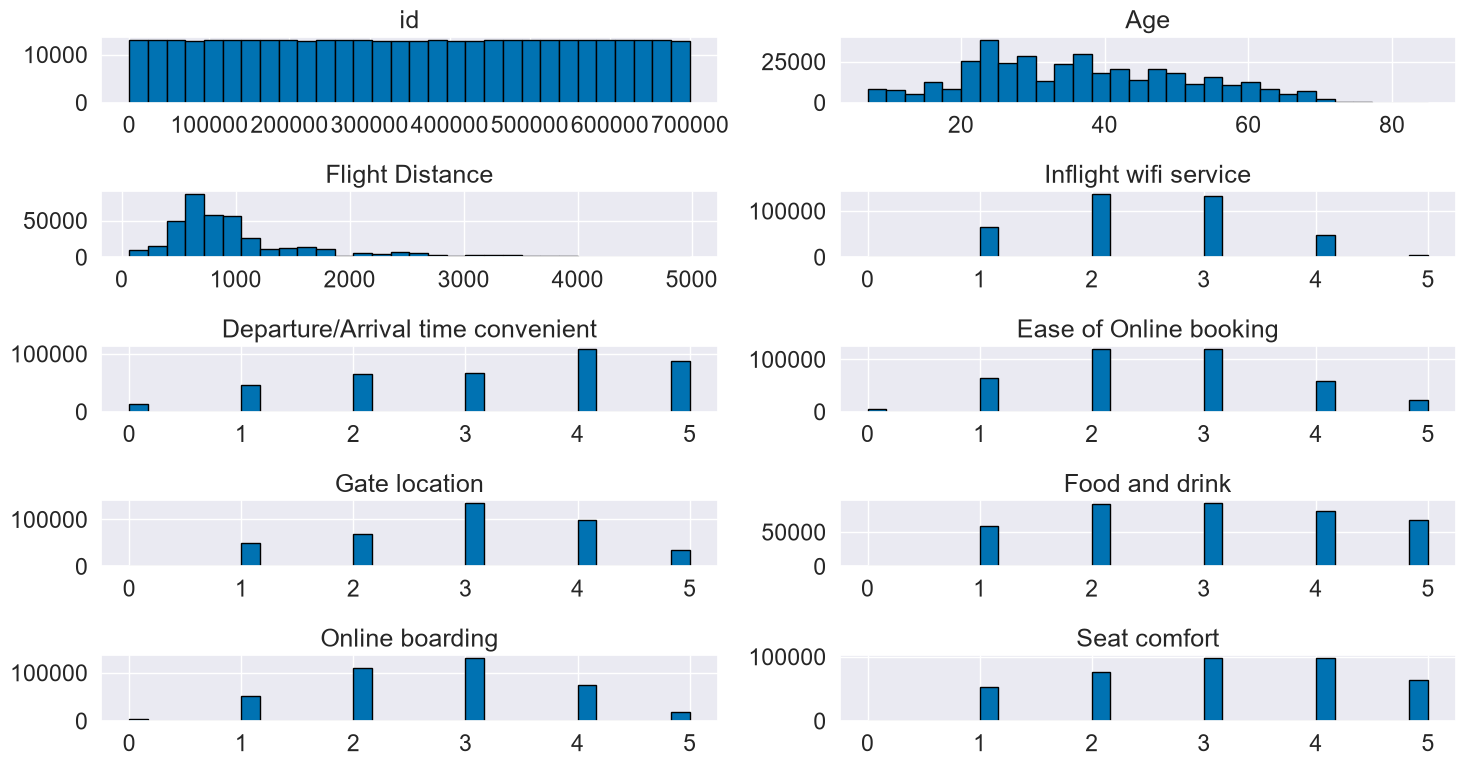

In [34]:
num_dissatisfied = dissatisfied_df.select_dtypes(include='number')

#plot numerical features

color = '#0072B2'

# grid size
nrows, ncols = 5, 2

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, 8))

axes = axes.flatten()

# Plot each numerical feature
for i, ax in enumerate(axes):
    if i >= len(num_dissatisfied.columns):
        ax.set_visible(False)  # hide unesed plots
        continue
    ax.hist(num_dissatisfied.iloc[:, i], bins=30, color=color, edgecolor='black')
    ax.set_title(num_dissatisfied.columns[i])

plt.tight_layout()
plt.show()

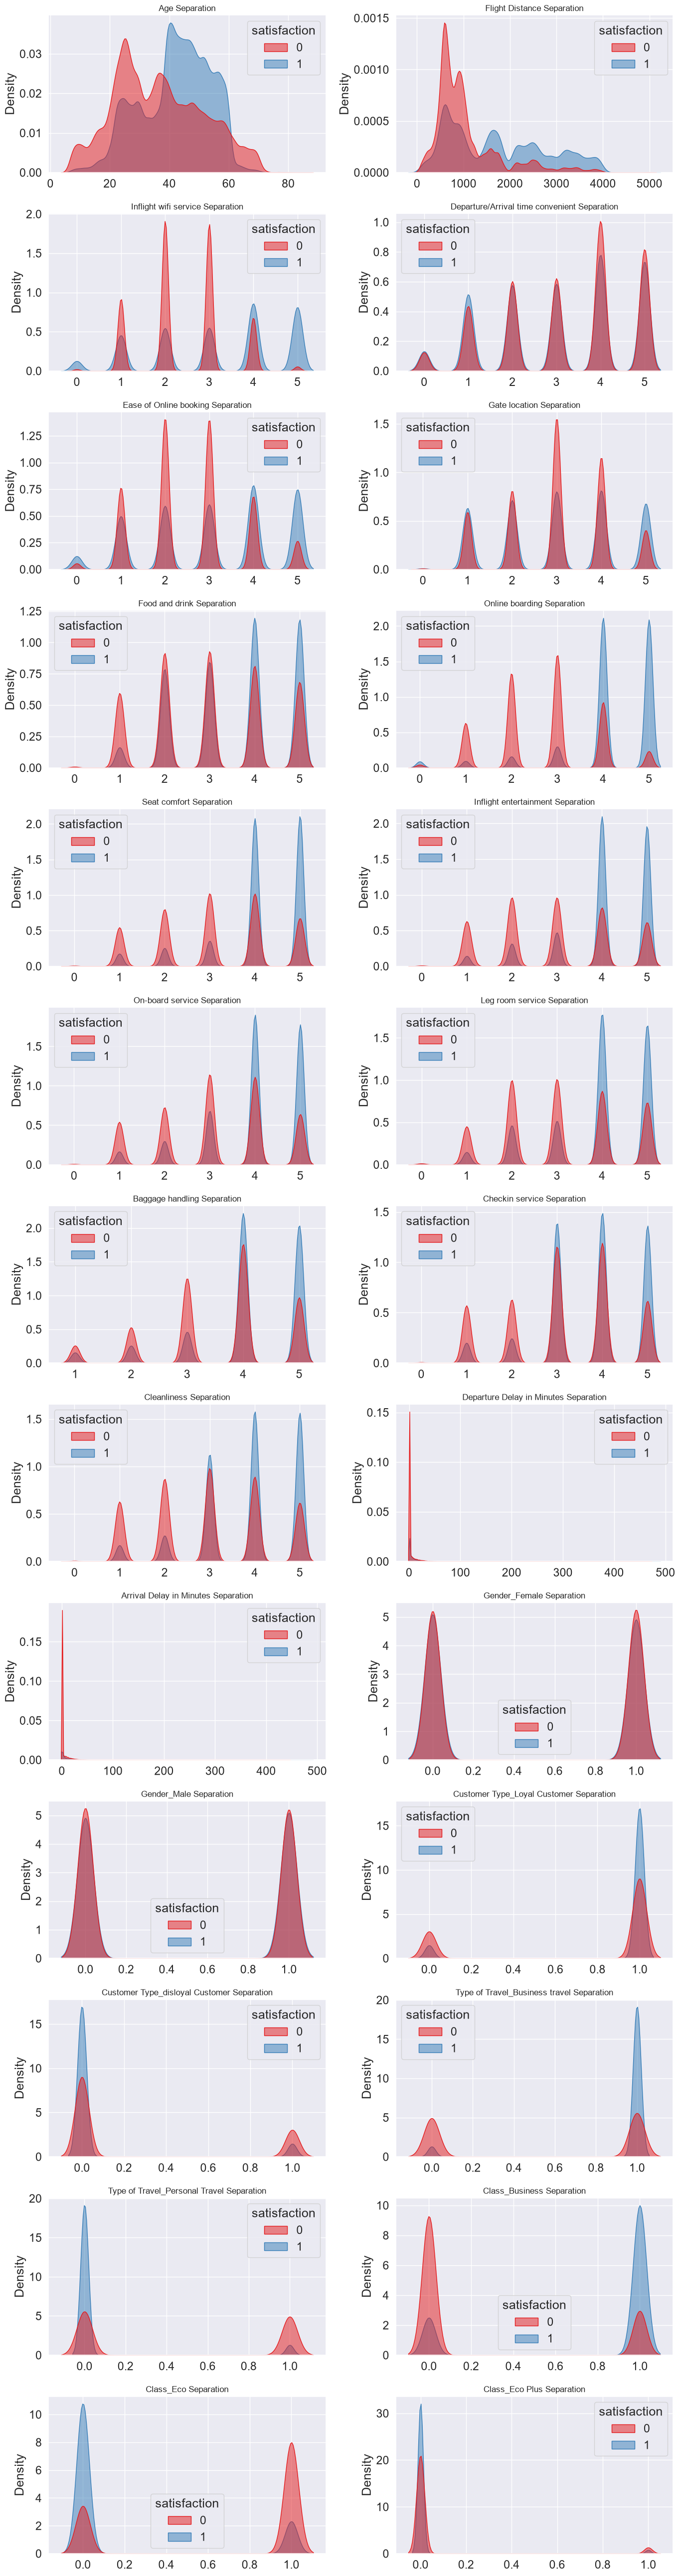

In [35]:
key_features = [col for col in num.columns if col in train_df.columns and col != 'satisfaction']

nrows = (len(key_features) + 1) // 2
fig, axes = plt.subplots(nrows=nrows, ncols=2, figsize=(14, 4 * nrows))
axes = np.array(axes).flatten()

if key_features:
    for i, col in enumerate(key_features):
        ax = axes[i]
        sns.kdeplot(
            data=train_df,
            x=col,
            hue=train_df['satisfaction'],
            fill=True,
            common_norm=False,
            palette='Set1',
            alpha=0.5,
            ax=ax
        )
        ax.set_title(f'{col} Separation', fontsize=12)
        ax.set_xlabel('')

    for ax in axes[len(key_features):]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.show()